In [1]:
import pandas as pd
import networkx as nx
import re
import os

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## How many Proteins Get Lost From GE-radical-scoring to KG-mapping

In [2]:
def radical_to_kgmap(scoring_path:str, 
                    graph_summary_path:str, 
                    kg:str='AD_KG',
                    dataset:str='adni',
                    scoring_method:str='ecdf'):
    
    df_scoring = pd.read_csv(scoring_path, index_col=0)
    df_graph_summary = pd.read_csv(graph_summary_path, index_col=0)
    labels = df_scoring['label'].to_list()

    non_zeros = (df_scoring.drop(columns=['label']) !=0).sum(axis=1)

    connections_count = df_graph_summary[['pos_edges', 'neg_edges']].sum(axis=1)


    difference = non_zeros - connections_count
    ratio = connections_count/non_zeros
    df_analysis = pd.DataFrame(
        {'Significantly_Expressed_Proteins': non_zeros,
        'Connected_to_KG_Proteins': connections_count,
        'Difference': difference,
        'Ratio': ratio},
        index = df_graph_summary.index)
    
    df_analysis['Connected_KG'] = kg
    df_analysis['Dataset'] = dataset
    df_analysis['Scoring_Method'] = scoring_method
    df_analysis['label']=labels
    
    return df_analysis

+ ADNI ecdf -> AD-KG

In [3]:
# adni ecdf -> AD-KG
scoring_path = "../CLEP_repeat/results/hpo_kge/AD_KG/ecdf_1.5/sample_scoring_ecdf.csv"
graph_summary_path = "../CLEP_repeat/results/hpo_kge/AD_KG/ecdf_1.5/Summary_adni_OldTarget_DiseaseKG_ecdf_1.5.csv"

df = radical_to_kgmap(scoring_path, graph_summary_path)
df

,Significantly_Expressed_Proteins,Connected_to_KG_Proteins,Difference,Ratio,Connected_KG,Dataset,Scoring_Method,label
116_S_1249,728,24,704,0.032967,AD_KG,adni,ecdf,0
037_S_4410,1858,79,1779,0.042519,AD_KG,adni,ecdf,0
006_S_4153,364,22,342,0.060440,AD_KG,adni,ecdf,1
116_S_1232,248,6,242,0.024194,AD_KG,adni,ecdf,0
099_S_4205,398,12,386,0.030151,AD_KG,adni,ecdf,1
...,...,...,...,...,...,...,...,...
009_S_2381,521,29,492,0.055662,AD_KG,adni,ecdf,1
053_S_4557,244,9,235,0.036885,AD_KG,adni,ecdf,1
073_S_4300,388,11,377,0.028351,AD_KG,adni,ecdf,1
041_S_4014,1376,60,1316,0.043605,AD_KG,adni,ecdf,0


### The difference between disease and control group samples' over_expressed & connected genes

In [4]:
df_scoring = pd.read_csv(scoring_path, index_col=0)
df_graph_summary = pd.read_csv(graph_summary_path, index_col=0)

In [5]:
labels = df_scoring['label']
df_score = df_scoring.drop(columns=['label'])
mask = df_score != 0

# Count the number of non-zero values per row
count = mask.sum(axis=1)

# Get the column names of non-zero values
names = mask.apply(lambda row: ', '.join(row.index[row]), axis=1)

df_score_genes = pd.DataFrame({
    'non_zero_count': count,
    'extreme_expressed_genes': names,
    'label':labels
}, index=df.index)
df_score_genes


,non_zero_count,extreme_expressed_genes,label
116_S_1249,728,"A4GALT, ACADL, ACOT12, ACOT6, ACPT, ACRC, ACTL...",0
037_S_4410,1858,"A4GNT, AAED1, AARD, AASDH, ABCA7, ABCB9, ABCC1...",0
006_S_4153,364,"ABCA6, ABCA9, ABCB4, ACADM, ADAM15, ADAM28, AD...",1
116_S_1232,248,"AADACL4, ABCD3, ACMSD, ACOT4, ADAMTS3, ADAMTSL...",0
099_S_4205,398,"ADAM21, ADAM21P1, ADAMTSL5, ADCYAP1, AGBL4, AL...",1
...,...,...,...
009_S_2381,521,"AANAT, ACBD7, ACO1, ACP6, ADAM32, ADAMTS14, AD...",1
053_S_4557,244,"A3GALT2, ABCA10, ACMSD, ACTA2, ACTL10, AGTR1, ...",1
073_S_4300,388,"AADACL2, ABCC6P1, ACSM3, ACTL6B, ADAMTS10, ADC...",1
041_S_4014,1376,"AASDHPPT, ABCB6, ABCC6P1, ABCF2, ABO, ACBD3, A...",0


In [ ]:
from matplotlib_venn import venn2

def convert_string_column_to_list(df,col_name):
    # convert the string column to a list of proteins
    disease_sample_dict = {}
    control_sample_dict = {}
    for index, row in df.iterrows():
        # Split the string and clean whitespace
        proteins = [p.strip() for p in row[col_name].split(',')]
        if row['label'] == 0:
            control_sample_dict[index]=proteins
        else:
            disease_sample_dict[index] = proteins
    return disease_sample_dict, control_sample_dict

def get_common_proteins(sample_protein_dict:dict):
    
    disease_proteins = {}
    for pr_list in sample_protein_dict.values():
        for pr in pr_list:
            if pr not in disease_proteins:
                disease_proteins[pr]=1
            else:
                disease_proteins[pr]+=1

    disease_proteins = dict(sorted(disease_proteins.items(), key=lambda x: x[1], reverse=True))

    return disease_proteins

def plot_venn2(set1, set2, labels=('Group A', 'Group B'), title="Comparison of Protein Sets"):
    
    # Convert lists to sets to ensure uniqueness
    s1 = set(set1)
    s2 = set(set2)
    
    # Create the plot
    plt.figure(figsize=(6, 6))
    venn2((s1, s2), set_labels=labels)
    
    plt.title(title)
    plt.show()


In [7]:
disease_scoring_dict, control_scoring_dict = convert_string_column_to_list(df_score_genes,col_name='extreme_expressed_genes')

disease_proteins=get_common_proteins(disease_scoring_dict)
control_proteins=get_common_proteins(control_scoring_dict)
control_proteins

{'OR51B5': 9,
 'RNASE10': 9,
 'ASPHD1': 8,
 'C20ORF144': 8,
 'C4ORF47': 8,
 'ITGA11': 8,
 'OR4C46': 8,
 'PRPH': 8,
 'PSENEN': 8,
 'TMEM190': 8,
 'TMEM27': 8,
 'WDR88': 8,
 'ANXA2P3': 8,
 'AVPR1B': 8,
 'DDX10': 8,
 'DNM1P35': 8,
 'GAGE5': 8,
 'HDAC10': 8,
 'NCAM2': 8,
 'OR4C45': 8,
 'RASL12': 8,
 'SNORA5B': 8,
 'SORCS2': 8,
 'SPTBN4': 8,
 'C2CD4A': 8,
 'DENND2A': 8,
 'OR4K17': 8,
 'POM121L8P': 8,
 'XRCC3': 8,
 'C19ORF47': 8,
 'C9ORF169': 8,
 'CCDC163P': 8,
 'CPSF3': 8,
 'CPT2': 8,
 'DEFB103A': 8,
 'ENSG00000178069': 8,
 'FAM69B': 8,
 'GSTA5': 8,
 'LOC100129717': 8,
 'MED12': 8,
 'MS4A10': 8,
 'PHKA2': 8,
 'PMCHL1': 8,
 'RAN': 8,
 'SH2D2A': 8,
 'USP20': 8,
 'C9ORF172': 8,
 'CSPG4P1Y': 8,
 'LOC101929877': 8,
 'PAQR9': 8,
 'PCDHB14': 8,
 'VWA2': 8,
 'CLDN22': 8,
 'CTCFL': 8,
 'CXORF64': 8,
 'SLC22A23': 8,
 'WT1': 8,
 'ATAD5': 8,
 'CHGB': 8,
 'CISD3': 8,
 'CSF1': 8,
 'DIAPH3': 8,
 'KIF20A': 8,
 'LOC100996725': 8,
 'ONECUT2': 8,
 'PDILT': 8,
 'SUGCT': 8,
 'TGM5': 8,
 'TRIM49': 8,
 'TRIM49B':

In [8]:
disease_proteins

{'AHNAK2': 52,
 'NOX3': 51,
 'RHOXF2': 48,
 'RHOXF2B': 48,
 'DIDO1': 47,
 'LINC00474': 47,
 'OR9G1': 46,
 'OR9G9': 46,
 'RP11-299L17.3*': 46,
 'JPH3': 46,
 'CRNN': 44,
 'TMEM225': 44,
 'DOK5': 44,
 'TREM2': 43,
 'TNFSF18': 42,
 'CA5A': 42,
 'NIM1*': 42,
 'RSPH9': 42,
 'LRRC27': 42,
 'PARP8': 42,
 'ZKSCAN2': 42,
 'C8ORF4': 42,
 'ATP6V0D2': 41,
 'FAXDC2': 41,
 'ISG20L2': 41,
 'LINC00612': 41,
 'DRD3': 41,
 'GPR101': 40,
 'GRB14': 40,
 'ACP2': 40,
 'LRRC70': 40,
 'MICA': 40,
 'NOD1': 40,
 'CCR8': 40,
 'OR5AU1': 39,
 'BARX1': 39,
 'CTH': 39,
 'TAPT1': 39,
 'SLX4IP': 39,
 'C16ORF72': 39,
 'PDPR': 39,
 'AOAH': 39,
 'F13A1': 39,
 'TLCD1': 39,
 'COL8A2': 38,
 'DKK1': 38,
 'C20ORF201': 38,
 'ENSG00000174495': 38,
 'ARSH': 38,
 'GNAZ': 38,
 'LINGO4': 38,
 'RGS7BP': 38,
 'C1ORF56': 38,
 'FYB': 38,
 'HGSNAT': 38,
 'COL27A1': 37,
 'IP6K2': 37,
 'LOC100287010': 37,
 'RTKN2': 37,
 'BPIFA4P': 37,
 'FETUB': 37,
 'JPH2': 37,
 'C6': 37,
 'UBB': 37,
 'TPPP': 37,
 'TMEM98': 37,
 'CALD1': 37,
 'CCDC103': 37

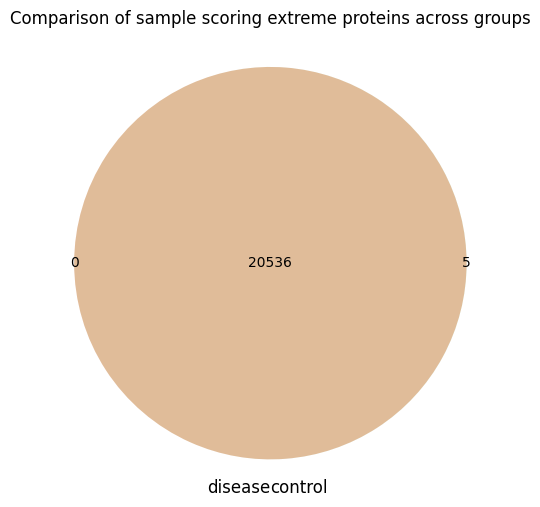

In [38]:
plot_venn2(disease_proteins, control_proteins, labels=('disease', 'control'), title="Comparison of sample scoring extreme proteins across groups")

In [9]:
import ast

df_graph_summary

,pos_edges,neg_edges,linked_nodes,label
116_S_1249,9,15,"['p(HGNC:""APOE"")', 'p(HGNC:""ATF3"")', 'p(HGNC:""...",0
037_S_4410,37,42,"['p(HGNC:""ABCA7"")', 'p(HGNC:""ACE"")', 'p(HGNC:""...",0
006_S_4153,17,5,"['p(HGNC:""APBB2"")', 'p(HGNC:""BACE2"")', 'p(MGI:...",1
116_S_1232,6,0,"['p(HGNC:""ADIPOQ"")', 'p(RGD:""Crhr2"")', 'p(HGNC...",0
099_S_4205,3,9,"['p(HGNC:""BAG1"")', 'p(HGNC:""CAMK2A"")', 'p(HGNC...",1
...,...,...,...,...
009_S_2381,26,3,"['p(HGNC:""APOE"")', 'p(HGNC:""ARMS2"")', 'p(MGI:""...",1
053_S_4557,6,3,"['p(HGNC:""AGTR1"")', 'p(HGNC:""DAB1"")', 'p(HGNC:...",1
073_S_4300,6,5,"['p(HGNC:""ATF4"")', 'p(MGI:""Atf4"")', 'p(HGNC:""C...",1
041_S_4014,40,20,"['p(HGNC:""APBA3"")', 'p(HGNC:""APOH"")', 'p(HGNC:...",0


In [10]:
df_graph_summary['ast_linked_nodes'] = df_graph_summary['linked_nodes'].apply(ast.literal_eval)

control_graph_dict = df_graph_summary[df_graph_summary['label']==0]['ast_linked_nodes'].to_dict()
disease_graph_dict = df_graph_summary[df_graph_summary['label']==1]['ast_linked_nodes'].to_dict()

control_graph_proteins = get_common_proteins(control_graph_dict)
disease_graph_proteins = get_common_proteins(disease_graph_dict)
control_graph_proteins

{'p(HGNC:"PSENEN")': 8,
 'p(HGNC:"CSF1")': 8,
 'p(HGNC:"CHRNA9")': 8,
 'p(RGD:"Chrna9")': 8,
 'p(HGNC:"BCHE")': 8,
 'p(HGNC:"APOE")': 7,
 'p(HGNC:"ATF3")': 7,
 'p(HGNC:"CALB1")': 7,
 'p(HGNC:"CDH2")': 7,
 'p(MGI:"Cdh2")': 7,
 'p(HGNC:"CHRNB3")': 7,
 'p(RGD:"Chrnb3")': 7,
 'p(HGNC:"COX8A")': 7,
 'p(HGNC:"CPEB1")': 7,
 'p(HGNC:"FBXL2")': 7,
 'p(HGNC:"GABRA2")': 7,
 'p(HGNC:"GRIA2")': 7,
 'p(HGNC:"HES5")': 7,
 'p(HGNC:"IL2")': 7,
 'p(HGNC:"ITGA3")': 7,
 'p(HGNC:"MAT1A")': 7,
 'p(HGNC:"MLLT11")': 7,
 'p(HGNC:"MMP2")': 7,
 'p(MGI:"Mmp2")': 7,
 'p(HGNC:"PLA2G2A")': 7,
 'p(HGNC:"PLAT")': 7,
 'p(HGNC:"PSEN2")': 7,
 'p(HGNC:"RYR3")': 7,
 'p(HGNC:"ABCA7")': 7,
 'p(HGNC:"ACE")': 7,
 'p(HGNC:"ANXA1")': 7,
 'p(HGNC:"APBB3")': 7,
 'p(HGNC:"APOC3")': 7,
 'p(HGNC:"ARC")': 7,
 'p(MGI:"Arc")': 7,
 'p(HGNC:"ARRB2")': 7,
 'p(MGI:"Atg5")': 7,
 'p(HGNC:"CACNG8")': 7,
 'p(HGNC:"CAMK2A")': 7,
 'p(HGNC:"CAMK2B")': 7,
 'p(HGNC:"CAPN2")': 7,
 'p(HGNC:"CCR2")': 7,
 'p(HGNC:"CD200R1")': 7,
 'p(HGNC:"CD276")': 7,
 

In [11]:
disease_graph_proteins

{'p(MGI:"Trem2")': 43,
 'p(HGNC:"TREM2")': 43,
 'p(HGNC:"DKK1")': 38,
 'p(MGI:"Dkk1")': 38,
 'p(RGD:"Dkk1")': 38,
 'p(HGNC:"CDKN1A")': 36,
 'p(HGNC:"MTOR")': 35,
 'p(HGNC:"IL2")': 32,
 'p(HGNC:"TTR")': 32,
 'p(HGNC:"GALR1")': 32,
 'p(HGNC:"NOS1")': 31,
 'p(HGNC:"CCR1")': 31,
 'p(HGNC:"CXCL10")': 31,
 'p(MGI:"Cxcl10")': 31,
 'p(HGNC:"JAG1")': 31,
 'p(HGNC:"CAST")': 31,
 'p(HGNC:"THBS1")': 31,
 'p(MGI:"Chat")': 31,
 'p(HGNC:"CHAT")': 31,
 'p(HGNC:"PTK7")': 30,
 'p(HGNC:"ARC")': 30,
 'p(MGI:"Arc")': 30,
 'p(HGNC:"SPHK1")': 30,
 'p(HGNC:"SPTLC3")': 30,
 'p(HGNC:"TRPV1")': 30,
 'p(HGNC:"BAG1")': 29,
 'p(MGI:"Lcn2")': 29,
 'p(HGNC:"SDC2")': 29,
 'p(HGNC:"PAFAH2")': 29,
 'p(RGD:"Crhr2")': 28,
 'p(HGNC:"GABRG3")': 28,
 'p(HGNC:"C2")': 28,
 'p(HGNC:"CYP2E1")': 28,
 'p(RGD:"Cyp2e1")': 28,
 'p(HGNC:"IRS2")': 28,
 'p(HGNC:"ALB")': 28,
 'p(HGNC:"CACNG5")': 27,
 'p(HGNC:"JUND")': 27,
 'p(HGNC:"NRCAM")': 27,
 'p(HGNC:"MMP3")': 27,
 'p(HGNC:"FAS")': 27,
 'p(HGNC:"YY1")': 27,
 'p(HGNC:"IL34")': 27,
 'p

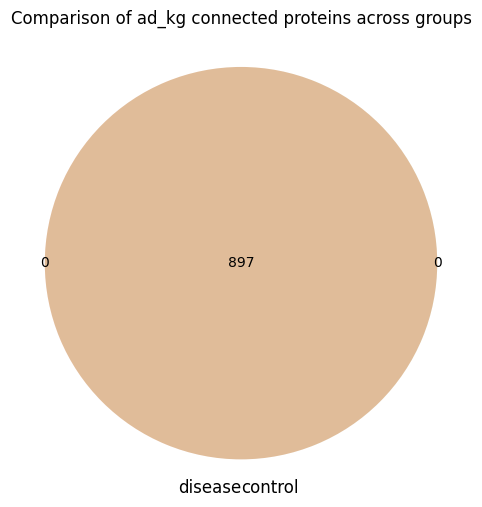

In [ ]:
plot_venn2(disease_graph_proteins.keys(), control_graph_proteins.keys(), labels=('disease', 'control'), title="Comparison of ad_kg connected proteins across groups")

## Average of neighborhood node degree

# To AD-KG

In [8]:
scoring_types = ['ecdf', 'std', 'all']
datasets = ['adni', 'geo']
kgs = ['AD_KGs', 'Prime_KGs', 'PPI_KGs']

dfs = {}
for dataset in datasets:
    # to store dfs
    dfs[dataset]=[]

    for kg in kgs:
        if dataset == 'adni':
            base_scoring_path = "../data/ADNI/sample_scoring"
        else:
            base_scoring_path = "../data/GEO/GSE33000_ad_hd/sample_scoring"
        
        for scoring in scoring_types:

            scoring_path = os.path.join(base_scoring_path, f'sample_scoring_{scoring}.csv')
            graph_summary_path = f"../datasets/new/{kg}/Summary_{dataset}_ADKG_{scoring}.csv"

            if not os.path.exists(scoring_path) or not os.path.exists(graph_summary_path):
                print(f"Path {scoring_path} or {graph_summary_path} Not Exists!")
                continue

            df = radical_to_kgmap(scoring_path = scoring_path,
                                  graph_summary_path = graph_summary_path,
                                  kg=kg,
                                  dataset=dataset,
                                  scoring_method=scoring)
            dfs[dataset].append(df)

In [9]:
len(dfs['adni'])

9

In [6]:
dfs['adni']

[            Significantly_Expressed_Proteins  Connected_to_KG_Proteins  \
 116_S_1249                              2080                        68   
 037_S_4410                              5083                       217   
 006_S_4153                              1095                        45   
 116_S_1232                              1137                        33   
 128_S_0205                              3794                       148   
 ...                                      ...                       ...   
 014_S_4668                              2087                        64   
 130_S_0289                              2430                        91   
 009_S_2381                              1648                        65   
 041_S_4014                              4038                       153   
 007_S_0101                              1768                        82   
 
             Difference     Ratio Connected_KG Dataset Scoring_Method  
 116_S_1249        2012  0

## Visualize

In [10]:
def plot_df(dfs:dict, dataset:str='adni'):
    # 1. Concatenate the DataFrames 
    # pd.concat merges list of dfs vertically.
    # Reset the index to keep  patient idx as a usable column.
    df_list = dfs['adni']
    master_df = pd.concat(df_list).reset_index().rename(columns={'index': 'Patient_ID'})

    print("Master DataFrame Shape:", master_df.shape)

    sns.set_theme(style="whitegrid")
    plt.rcParams['figure.dpi'] = 150


    # --- VISUALIZATION 1: Boxplot with Min, Max, Mean annotations ---
    g1 = sns.catplot(
        data=master_df, 
        x="Scoring_Method", 
        y="Connected_to_KG_Proteins", 
        col="Connected_KG", 
        kind="box",
        palette="Set2",
        height=6, 
        aspect=0.9
    )
    g1.set_titles("{col_name}")
    g1.set_axis_labels("Scoring Method", "Connected to KG Proteins")
    plt.subplots_adjust(top=0.82)
    g1.fig.suptitle("Distribution of Connected KG Proteins\n(With Min, Mean, Max Annotations)", fontsize=14, weight='bold')

    # Loop through each subplot/column to inject the text labels
    for kg_name, ax in g1.axes_dict.items():
        # Filter master data to match only this specific subplot's Knowledge Graph
        sub_df = master_df[master_df['Connected_KG'] == kg_name]
        
        # Get the x-axis categories in order
        categories = [text.get_text() for text in ax.get_xticklabels()]
        
        # Calculate stats for each category (Scoring Method)
        for i, cat in enumerate(categories):
            cat_data = sub_df[sub_df['Scoring_Method'] == cat]['Connected_to_KG_Proteins']
            
            if len(cat_data) > 0:
                v_min = cat_data.min()
                v_max = cat_data.max()
                v_mean = cat_data.mean()
                
                # Place text labels next to the boxes. 
                # i represents the X-coordinate. We offset slightly to the right (i + 0.22)
                # We use an edge color/bbox to ensure it remains readable over gridlines
                text_str = f"Max: {v_max:.0f}\nMean: {v_mean:.1f}\nMin: {v_min:.0f}"
                ax.text(i + 0.24, v_mean, text_str, color='black', weight='semibold',
                        fontsize=8, ha='left', va='center',
                        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))


    # --- VISUALIZATION 2: Violin plot with Min, Max, Mean annotations ---
    g2 = sns.catplot(
        data=master_df, 
        x="Scoring_Method", 
        y="Ratio", 
        col="Connected_KG", 
        kind="violin",
        palette="muted",
        inner="quart",
        height=6, 
        aspect=0.9
    )
    g2.set_titles("{col_name}")
    g2.set_axis_labels("Scoring Method", "Ratio Value")
    plt.subplots_adjust(top=0.82)
    g2.fig.suptitle("Ratio Analysis across Configurations\n(With Min, Mean, Max Annotations)", fontsize=14, weight='bold')

    # Repeat the text injection process for the second grid
    for kg_name, ax in g2.axes_dict.items():
        sub_df = master_df[master_df['Connected_KG'] == kg_name]
        categories = [text.get_text() for text in ax.get_xticklabels()]
        
        for i, cat in enumerate(categories):
            cat_data = sub_df[sub_df['Scoring_Method'] == cat]['Ratio']
            
            if len(cat_data) > 0:
                v_min = cat_data.min()
                v_max = cat_data.max()
                v_mean = cat_data.mean()
                
                # Format decimals to 3 decimal places for ratios since they are small float numbers
                text_str = f"Max: {v_max:.3f}\nMean: {v_mean:.3f}\nMin: {v_min:.3f}"
                ax.text(i + 0.26, v_mean, text_str, color='black', weight='semibold',
                        fontsize=8, ha='left', va='center',
                        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))

    plt.show()

    return master_df

In [8]:
for df in dfs['adni']:
    print(df)

            Significantly_Expressed_Proteins  Connected_to_KG_Proteins  \
116_S_1249                              2080                        68   
037_S_4410                              5083                       217   
006_S_4153                              1095                        45   
116_S_1232                              1137                        33   
128_S_0205                              3794                       148   
...                                      ...                       ...   
014_S_4668                              2087                        64   
130_S_0289                              2430                        91   
009_S_2381                              1648                        65   
041_S_4014                              4038                       153   
007_S_0101                              1768                        82   

            Difference     Ratio Connected_KG Dataset Scoring_Method  
116_S_1249        2012  0.032692  Patien

Master DataFrame Shape: (4095, 8)


/tmp/ipykernel_82683/1103258891.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g1 = sns.catplot(
/tmp/ipykernel_82683/1103258891.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g2 = sns.catplot(


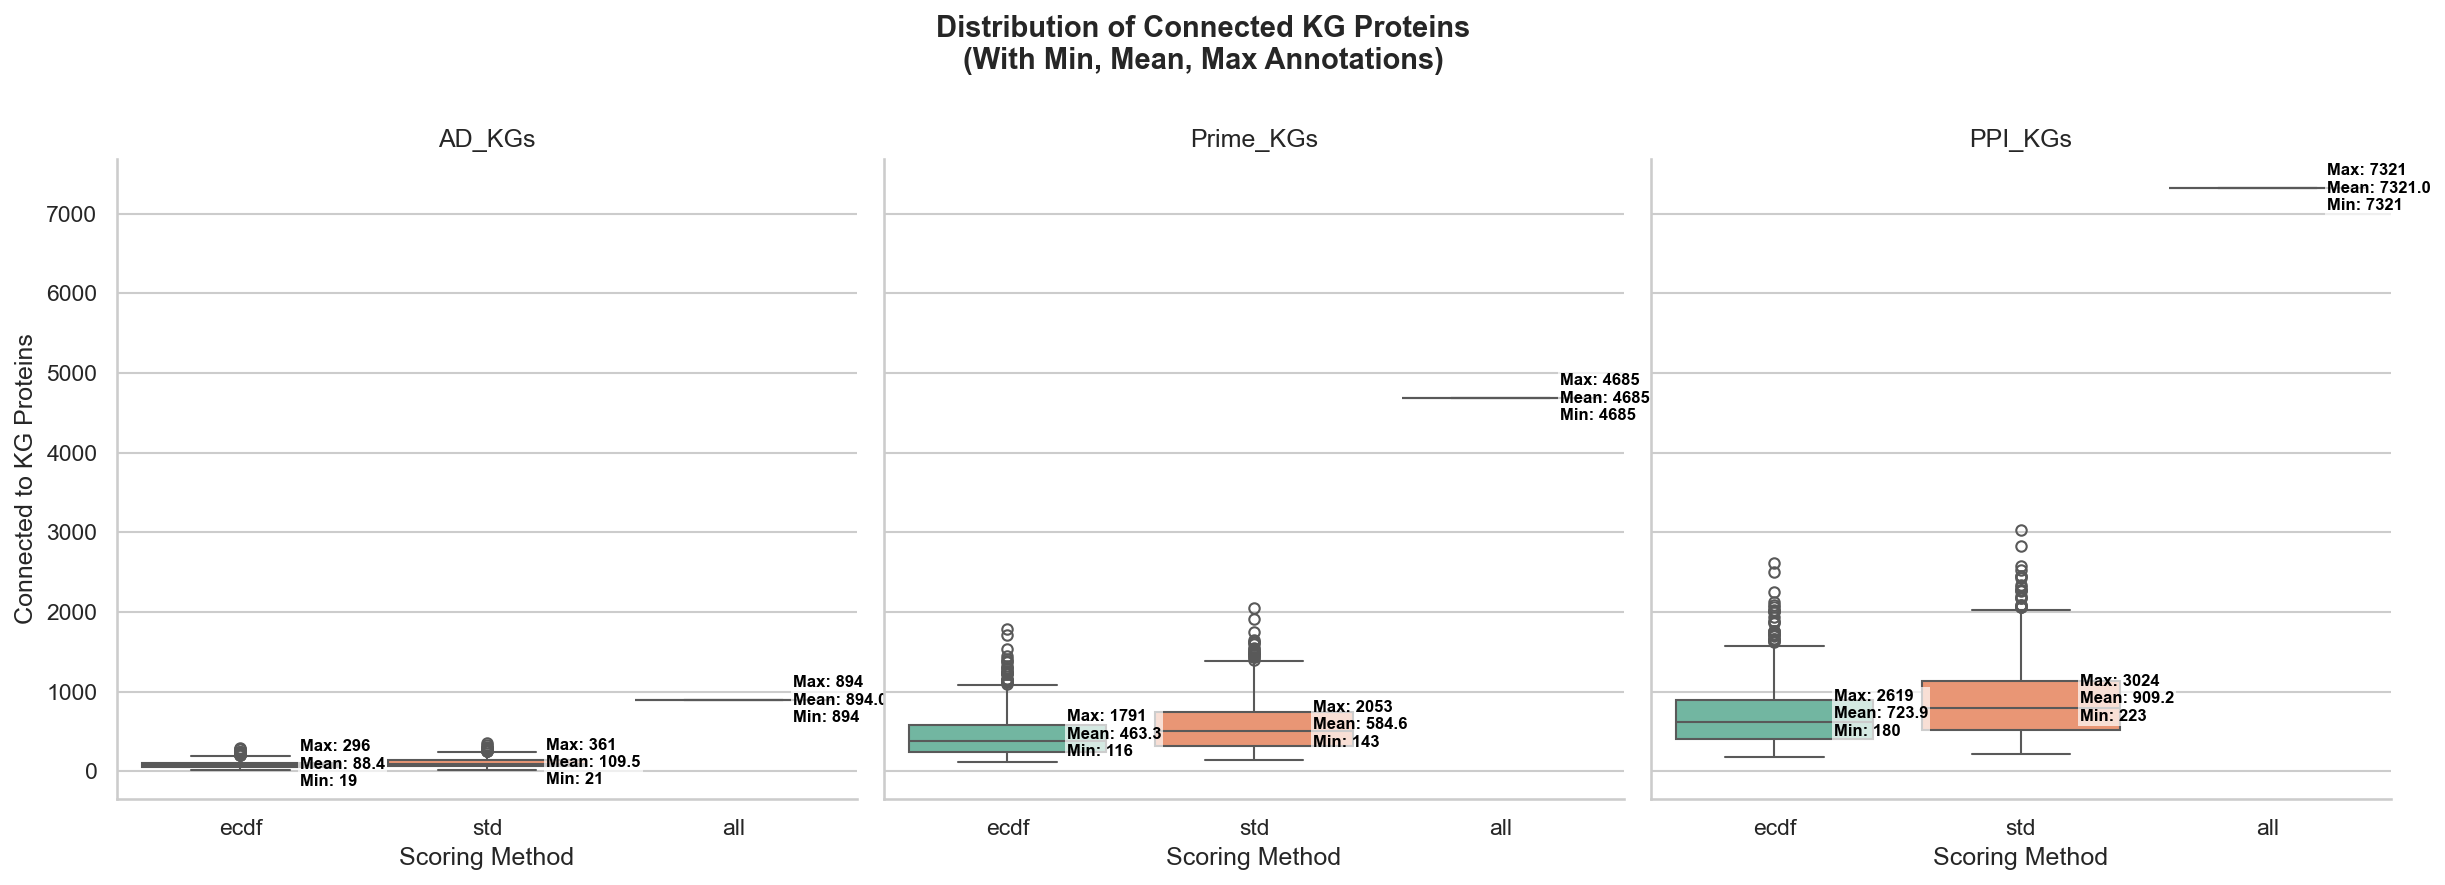

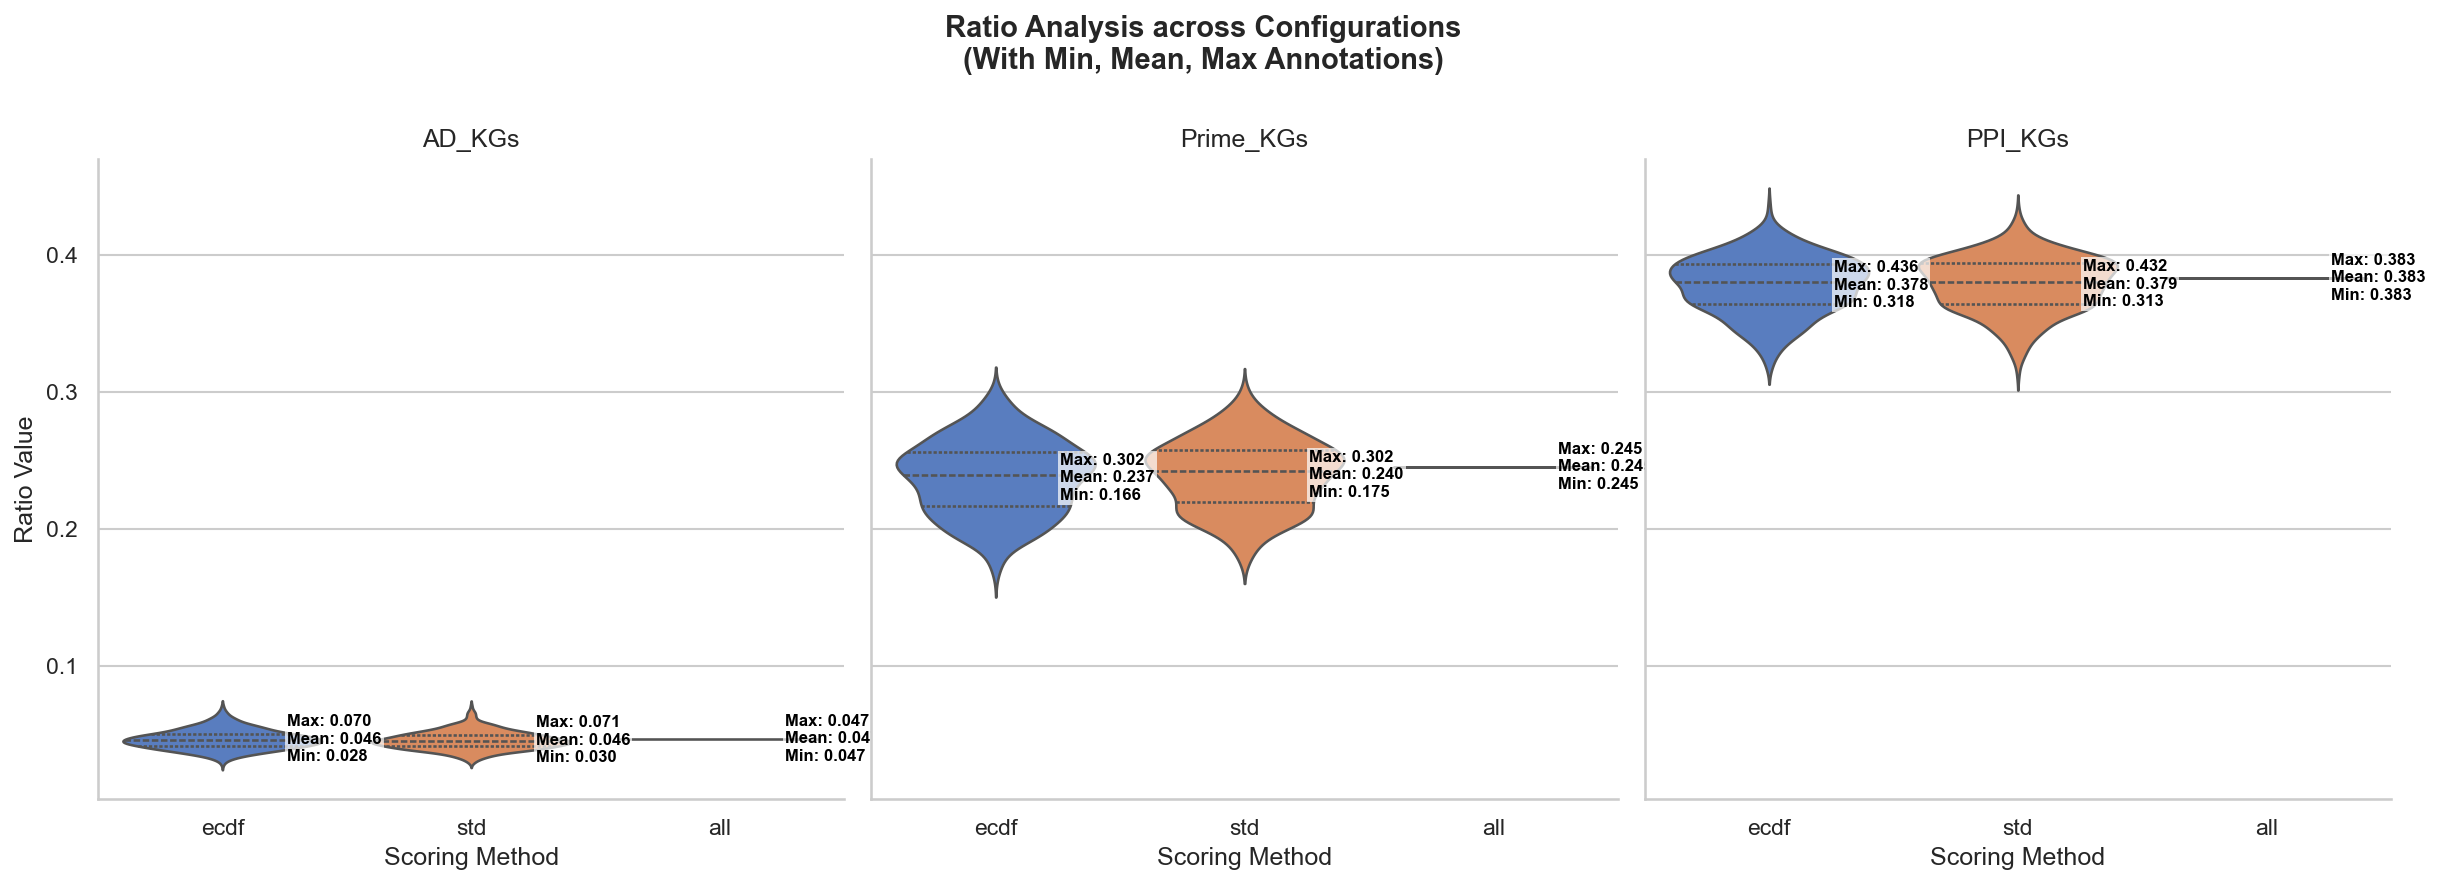

,Patient_ID,Significantly_Expressed_Proteins,Connected_to_KG_Proteins,Difference,Ratio,Connected_KG,Dataset,Scoring_Method
0,116_S_1249,2080,74,2006,0.035577,AD_KGs,adni,ecdf
1,037_S_4410,5083,243,4840,0.047806,AD_KGs,adni,ecdf
2,006_S_4153,1095,57,1038,0.052055,AD_KGs,adni,ecdf
3,116_S_1232,1137,39,1098,0.034301,AD_KGs,adni,ecdf
4,128_S_0205,3794,193,3601,0.050870,AD_KGs,adni,ecdf
...,...,...,...,...,...,...,...,...
4090,014_S_4668,19100,7321,11779,0.383298,PPI_KGs,adni,all
4091,130_S_0289,19100,7321,11779,0.383298,PPI_KGs,adni,all
4092,009_S_2381,19100,7321,11779,0.383298,PPI_KGs,adni,all
4093,041_S_4014,19100,7321,11779,0.383298,PPI_KGs,adni,all


In [11]:
plot_df(dfs, 'adni')

Master DataFrame Shape: (4095, 8)


/tmp/ipykernel_82683/1103258891.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g1 = sns.catplot(
/tmp/ipykernel_82683/1103258891.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g2 = sns.catplot(


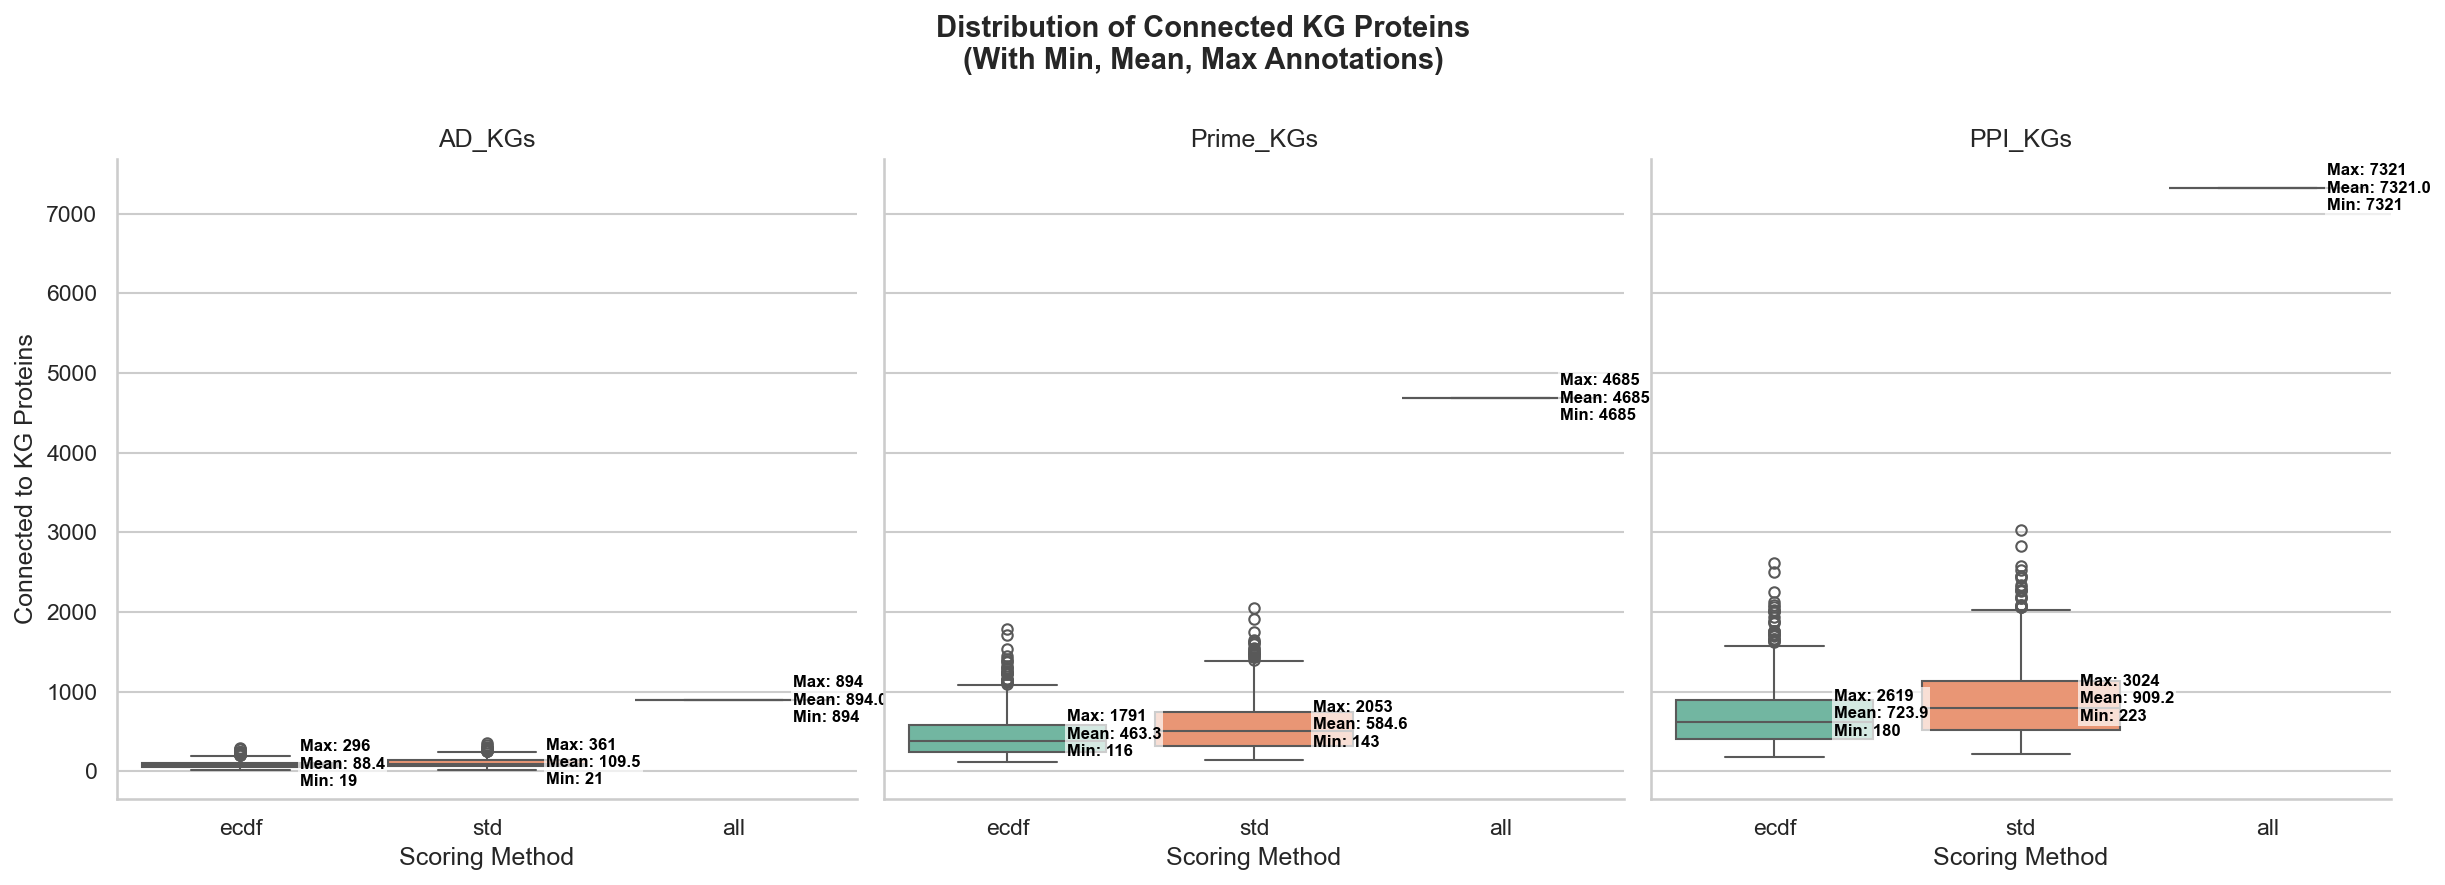

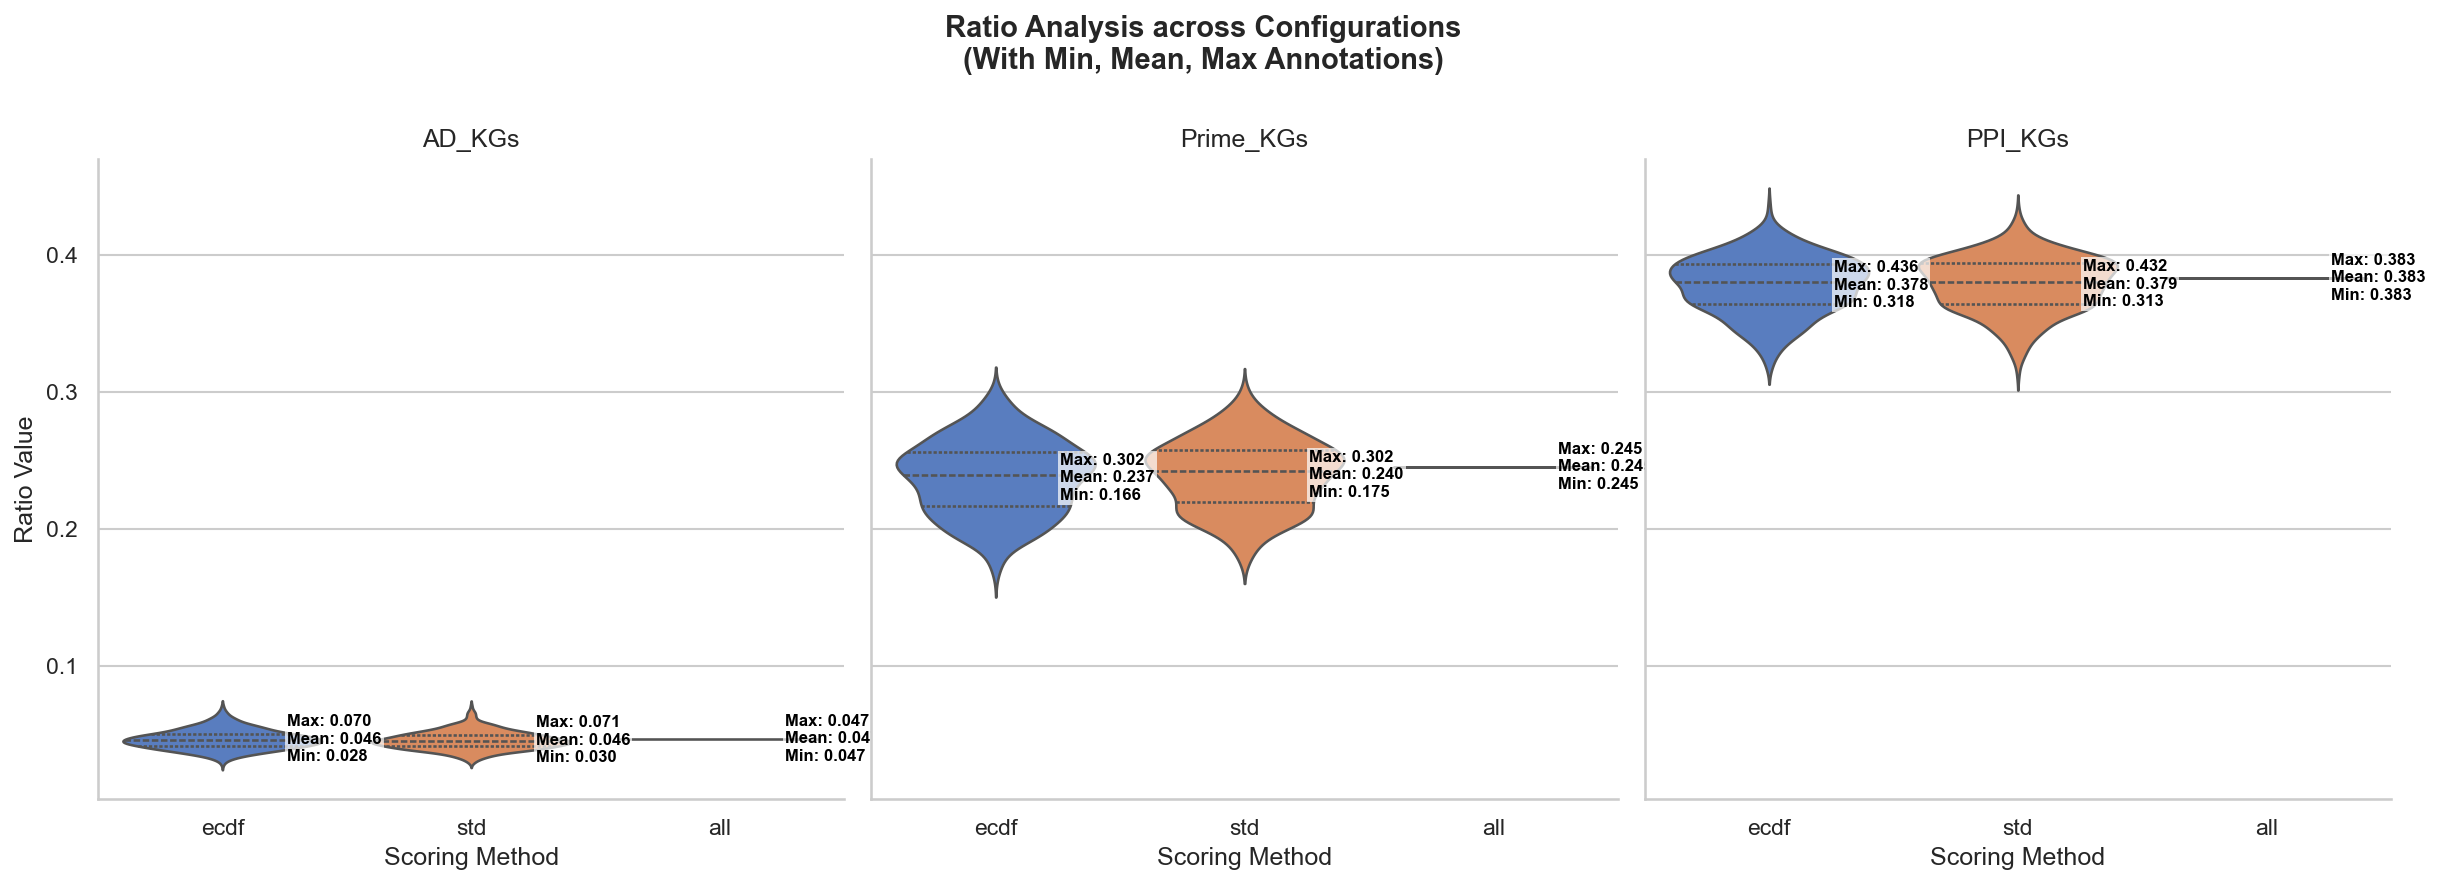

,Patient_ID,Significantly_Expressed_Proteins,Connected_to_KG_Proteins,Difference,Ratio,Connected_KG,Dataset,Scoring_Method
0,116_S_1249,2080,74,2006,0.035577,AD_KGs,adni,ecdf
1,037_S_4410,5083,243,4840,0.047806,AD_KGs,adni,ecdf
2,006_S_4153,1095,57,1038,0.052055,AD_KGs,adni,ecdf
3,116_S_1232,1137,39,1098,0.034301,AD_KGs,adni,ecdf
4,128_S_0205,3794,193,3601,0.050870,AD_KGs,adni,ecdf
...,...,...,...,...,...,...,...,...
4090,014_S_4668,19100,7321,11779,0.383298,PPI_KGs,adni,all
4091,130_S_0289,19100,7321,11779,0.383298,PPI_KGs,adni,all
4092,009_S_2381,19100,7321,11779,0.383298,PPI_KGs,adni,all
4093,041_S_4014,19100,7321,11779,0.383298,PPI_KGs,adni,all


In [12]:
plot_df(dfs, 'geo')